In [1]:
from util.read_txt import read_dod_ocv

In [2]:
path_to_txt = "./data/article/ocv.txt"
dod, ocv = read_dod_ocv(path_to_txt)

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Параметры
Q = 620e-3 * 3600          # As
R1 = 0.11
C1 = 2.35e3
R2_0 = 0.27
a1, a2, a3, a4, a5, a6 = 1e-9, 1, 1.47e-8, 5e-5, 1e-5, 5
hA = 3e-4
m = 0.03
Cp = 1000.0
mCp = m * Cp
Tamb = 37 + 273.15

# OCV(DOD) — замените на свои данные
dod_pts = dod
ocv_pts = ocv
def OCV(dod):
    return np.interp(dod, dod_pts, ocv_pts)

def current(t):
    I = 25e-6
    year = 365*24*3600
    for y in range(5):
        t0 = y*year + 30*24*3600
        for k in range(3):
            t_start = t0 + k*11
            t_end = t_start + 10
            if t_start <= t < t_end:
                I = 1.0
    return I

def dynamics(t, x):
    x1, x2, x3, x4 = x
    I = current(t)
    x1 = np.clip(x1, 0, 1)
    KR2 = a1 * x1**a2 + a3 * np.exp(-a4 / x3) + a5 * I**a6
    dx1 = I / Q
    dx2 = -x2/(R1*C1) + I/C1
    dx3 = hA/(mCp)*(Tamb - x3) + x4/(mCp)*I**2
    dx4 = KR2 * x4
    return np.array([dx1, dx2, dx3, dx4])

# Начальные условия
x = np.array([0.05, 0.0, Tamb, R2_0])

# Время
t_end = 5*365*24*3600
dt_base = 60.0          # базовый шаг между импульсами
dt_pulse = 0.1          # шаг во время импульса

t_list = [0.0]
x_list = [x.copy()]
V_list = [OCV(x[0]) - x[1] - x[3]*current(0)]

t = 0.0
while t < t_end:
    I = current(t)
    # выбираем шаг
    if I > 1e-3:        # во время импульса
        dt = dt_pulse
    else:
        dt = dt_base
    if t + dt > t_end:
        dt = t_end - t
    # Эйлер
    dx = dynamics(t, x)
    x = x + dt * dx
    x[0] = np.clip(x[0], 0, 1)
    t += dt
    t_list.append(t)
    x_list.append(x.copy())
    V_list.append(OCV(x[0]) - x[1] - x[3]*current(t))

t_arr = np.array(t_list)
x_arr = np.array(x_list)
V_arr = np.array(V_list)

# Графики
plt.figure()
plt.plot(t_arr/(365*24*3600), V_arr)
plt.xlabel('Time [year]')
plt.ylabel('Terminal voltage [V]')
plt.grid(True)

plt.figure()
plt.plot(t_arr/(365*24*3600), x_arr[:,0]*100)
plt.xlabel('Time [year]')
plt.ylabel('DOD [%]')
plt.grid(True)

plt.figure()
plt.plot(t_arr/(365*24*3600), x_arr[:,3])
plt.xlabel('Time [year]')
plt.ylabel('R2 [Ohm]')
plt.grid(True)

plt.show()

KeyboardInterrupt: 

In [16]:
path_to_txt = "data/datasheet/ocv_dod.txt"
dod, ocv = read_dod_ocv(path_to_txt)

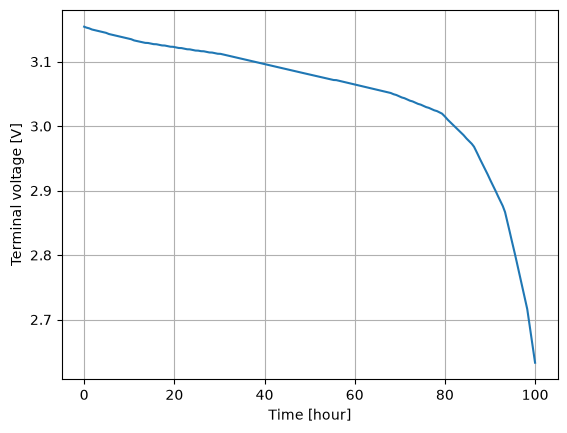

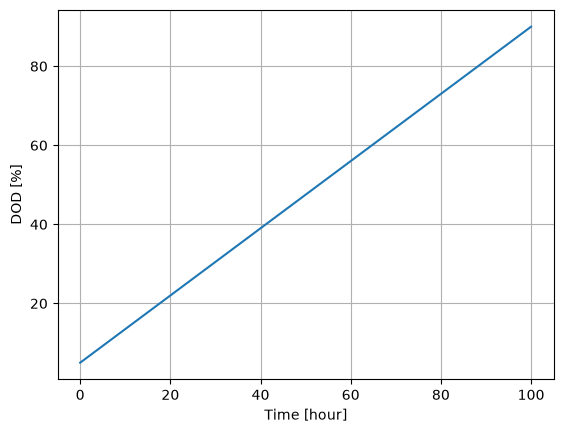

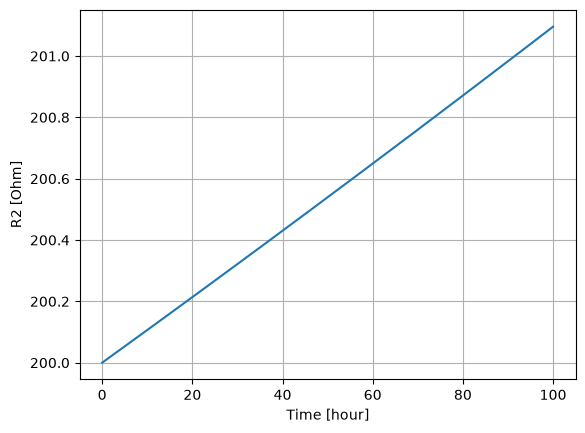

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# Параметры CR1632
# =========================================================
# --- Из даташита ---
Q      = 100e-3 * 3600      # 468 As (130 мА·ч)
R2_0   = 200.0               # Ом, начальное внутреннее сопротивление
m      = 1.8e-3             # кг
Tamb   = 23 + 273.15        # К

# --- Предположения ---
R1     = 0.5                # Ом
C1     = 50.0               # Ф
Cp     = 800.0             # Дж/(кг·К)
mCp    = m * Cp             # 1.8 Дж/К
h      = 1.0                # Дж/(с·м²·К)
A      = 1.5e-4             # м²
hA     = h * A              # 1.5e-4 Вт/К
mu     = 1e-4               # В/К

# --- Коэффициенты старения ---
a1, a2 = 1e-9, 1
a3     = 1.47e-8
a4     = 5*1e-5             # К
a5, a6 = 1e-5, 5

# --- Начальные условия ---
x1_0 = 0.05                 # DOD
x2_0 = 0.0                  # В
x3_0 = Tamb                 # К
x4_0 = R2_0                 # Ом

# --- Постоянный ток разряда ---
I_CONST = 850e-6            # 850 мкА

# =========================================================
# OCV(DOD) — таблица из даташита
# =========================================================
# Замените на свои оцифрованные значения
dod_pts = dod / 100
ocv_pts = ocv

def OCV(dod):
    return np.interp(dod, dod_pts, ocv_pts)

def current(t):
    """Постоянный ток разряда."""
    return I_CONST

# =========================================================
# Динамика
# =========================================================
def dynamics(x):
    x1, x2, x3, x4 = x
    I = I_CONST
    x1 = min(max(x1, 0.0), 1.0)

    KR2 = a1 * x1**a2 + a3 * np.exp(-a4 / x3) + a5 * I**a6

    dx1 = I / Q
    dx2 = -x2 / (R1 * C1) + I / C1
    dx3 = (hA / mCp) * (Tamb - x3) + (x4 / mCp) * I**2 + (mu / mCp) * x3 * I
    dx4 = KR2 * x4

    return np.array([dx1, dx2, dx3, dx4])

# =========================================================
# Выходное напряжение
# =========================================================
def terminal_voltage(x, I):
    x1, x2, x3, x4 = x
    return OCV(x1) + x2 / C1 + x4 * I

# =========================================================
# Интегрирование (метод Эйлера)
# =========================================================
t_end = 100 * 3600          # 100 часов
dt    = 0.5                 # шаг 1 с
n_steps = int(t_end / dt)

x = np.array([x1_0, x2_0, x3_0, x4_0], dtype=float)

t_arr = np.zeros(n_steps + 1)
x_arr = np.zeros((n_steps + 1, 4))
V_arr = np.zeros(n_steps + 1)

t_arr[0] = 0.0
x_arr[0] = x
V_arr[0] = terminal_voltage(x, I_CONST)

t = 0.0
for k in range(1, n_steps + 1):
    dx = dynamics(x)
    x = x + dt * dx
    x[0] = min(max(x[0], 0.0), 1.0)
    t += dt

    t_arr[k] = t
    x_arr[k] = x
    V_arr[k] = terminal_voltage(x, I_CONST)

# =========================================================
# Графики
# =========================================================
t_hours = t_arr / 3600

plt.figure()
plt.plot(t_hours, V_arr)
plt.xlabel('Time [hour]')
plt.ylabel('Terminal voltage [V]')
plt.grid(True)

plt.figure()
plt.plot(t_hours, x_arr[:, 0] * 100)
plt.xlabel('Time [hour]')
plt.ylabel('DOD [%]')
plt.grid(True)

plt.figure()
plt.plot(t_hours, x_arr[:, 3])
plt.xlabel('Time [hour]')
plt.ylabel('R2 [Ohm]')
plt.grid(True)

plt.show()